In [ ]:
# Step 1: Install required libraries
!pip install -q transformers accelerate scikit-learn pandas matplotlib seaborn

In [ ]:
# Step 2: Import libraries and load the resume dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Resume.csv")

print("Dataset Shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df[["ID", "Resume_str", "Category"]].head())

Dataset Shape: (2484, 4)
Columns: ['ID', 'Resume_str', 'Resume_html', 'Category']


,ID,Resume_str,Category
0,16852973,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,HR
1,22323967,"HR SPECIALIST, US HR OPERATIONS ...",HR
2,33176873,HR DIRECTOR Summary Over 2...,HR
3,27018550,HR SPECIALIST Summary Dedica...,HR
4,17812897,HR MANAGER Skill Highlights ...,HR


In [ ]:
# Step 3: Check job categories and missing values
print("Total Job Categories:", df["Category"].nunique())

print("\nResumes per Category:")
print(df["Category"].value_counts())

print("\nMissing Values:")
print(df[["Resume_str", "Category"]].isnull().sum())

Total Job Categories: 24

Resumes per Category:
Category
INFORMATION-TECHNOLOGY    120
BUSINESS-DEVELOPMENT      120
ADVOCATE                  118
CHEF                      118
ENGINEERING               118
ACCOUNTANT                118
FINANCE                   118
FITNESS                   117
AVIATION                  117
SALES                     116
BANKING                   115
HEALTHCARE                115
CONSULTANT                115
CONSTRUCTION              112
PUBLIC-RELATIONS          111
HR                        110
DESIGNER                  107
ARTS                      103
TEACHER                   102
APPAREL                    97
DIGITAL-MEDIA              96
AGRICULTURE                63
AUTOMOBILE                 36
BPO                        22
Name: count, dtype: int64

Missing Values:
Resume_str    0
Category      0
dtype: int64


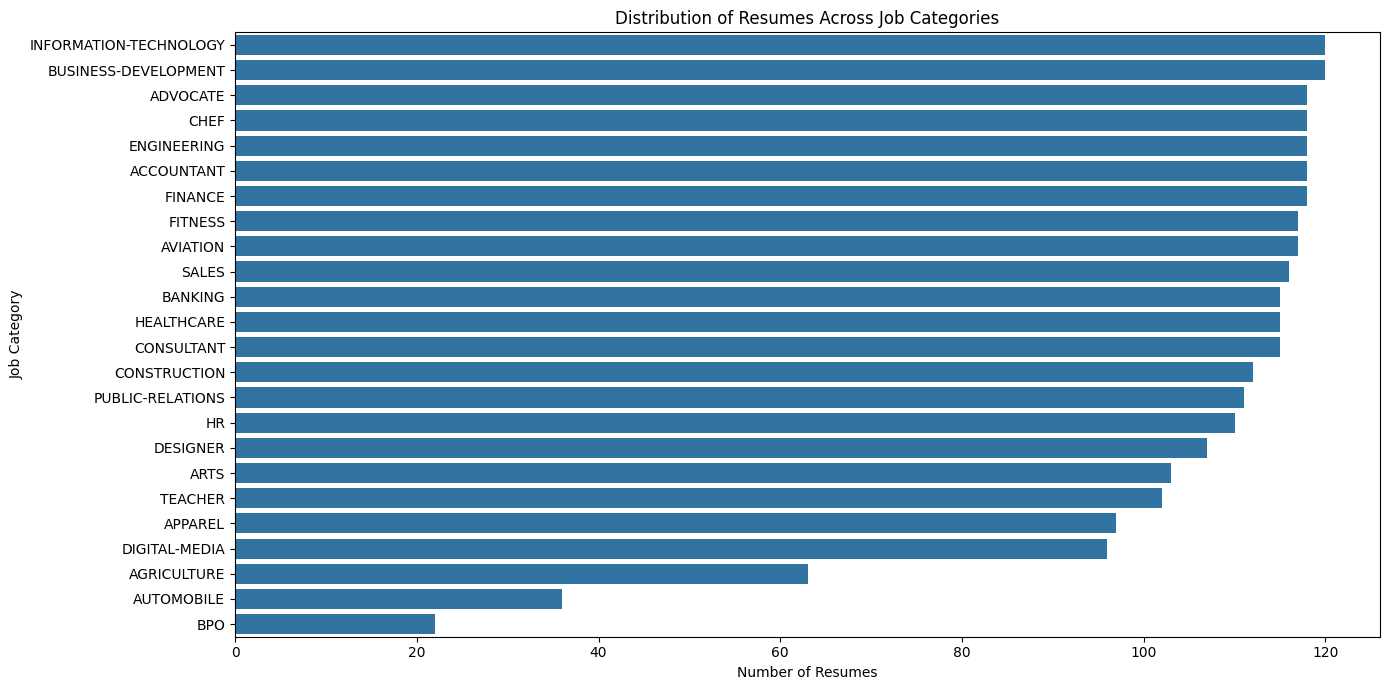

In [ ]:
# Step 4: Visualize the distribution of resumes across categories
plt.figure(figsize=(14, 7))

sns.countplot(
    data=df,
    y="Category",
    order=df["Category"].value_counts().index
)

plt.title("Distribution of Resumes Across Job Categories")
plt.xlabel("Number of Resumes")
plt.ylabel("Job Category")
plt.tight_layout()
plt.show()

In [ ]:
# Step 5: Clean the dataset and remove duplicate resumes
df = df[["Resume_str", "Category"]].copy()

df = df.dropna(subset=["Resume_str", "Category"])

df["Resume_str"] = df["Resume_str"].astype(str).str.strip()
df["Category"] = df["Category"].astype(str).str.strip()

df = df[
    (df["Resume_str"] != "") &
    (df["Category"] != "") &
    (df["Resume_str"].str.lower() != "nan") &
    (df["Category"].str.lower() != "nan")
]

df = df.drop_duplicates(subset=["Resume_str"])
df = df.reset_index(drop=True)

print("Clean Dataset Shape:", df.shape)
print("Total Job Categories:", df["Category"].nunique())

display(df.head())

Clean Dataset Shape: (2481, 2)
Total Job Categories: 24


,Resume_str,Category
0,HR ADMINISTRATOR/MARKETING ASSOCIATE\n\nHR ADM...,HR
1,"HR SPECIALIST, US HR OPERATIONS Summary ...",HR
2,HR DIRECTOR Summary Over 20 years e...,HR
3,"HR SPECIALIST Summary Dedicated, Driv...",HR
4,HR MANAGER Skill Highlights ...,HR


In [ ]:
# Step 6: Check the number of resumes in each category after cleaning
category_counts = df["Category"].value_counts()

print("Minimum Resumes in a Category:", category_counts.min())
print("Maximum Resumes in a Category:", category_counts.max())

display(category_counts.to_frame(name="Resume Count"))

Minimum Resumes in a Category: 22
Maximum Resumes in a Category: 120


,Resume Count
Category,
INFORMATION-TECHNOLOGY,120
BUSINESS-DEVELOPMENT,119
ADVOCATE,118
CHEF,118
ENGINEERING,118
ACCOUNTANT,118
FINANCE,117
FITNESS,117
SALES,116


In [ ]:
# Step 7: Convert job categories into numerical labels
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
df["label"] = label_encoder.fit_transform(df["Category"])

num_classes = len(label_encoder.classes_)

print("Total Classes:", num_classes)
print("Category Labels:")
for i, category in enumerate(label_encoder.classes_):
    print(i, ":", category)

Total Classes: 24
Category Labels:
0 : ACCOUNTANT
1 : ADVOCATE
2 : AGRICULTURE
3 : APPAREL
4 : ARTS
5 : AUTOMOBILE
6 : AVIATION
7 : BANKING
8 : BPO
9 : BUSINESS-DEVELOPMENT
10 : CHEF
11 : CONSTRUCTION
12 : CONSULTANT
13 : DESIGNER
14 : DIGITAL-MEDIA
15 : ENGINEERING
16 : FINANCE
17 : FITNESS
18 : HEALTHCARE
19 : HR
20 : INFORMATION-TECHNOLOGY
21 : PUBLIC-RELATIONS
22 : SALES
23 : TEACHER


In [ ]:
# Step 8: Split the dataset into training, validation and testing sets
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

print("Training Samples:", len(train_df))
print("Validation Samples:", len(val_df))
print("Testing Samples:", len(test_df))

Training Samples: 1736
Validation Samples: 372
Testing Samples: 373


In [ ]:
# Step 9: Load the pretrained BERT tokenizer
from transformers import AutoTokenizer

model_name = "google-bert/bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)

print("BERT Tokenizer Loaded Successfully!")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

BERT Tokenizer Loaded Successfully!


In [ ]:
# Step 10: Tokenize resume text for BERT
def tokenize_text(texts):
    return tokenizer(
        texts,
        padding="max_length",
        truncation=True,
        max_length=256,
        return_tensors="pt"
    )

train_encodings = tokenize_text(train_df["Resume_str"].tolist())
val_encodings = tokenize_text(val_df["Resume_str"].tolist())
test_encodings = tokenize_text(test_df["Resume_str"].tolist())

print("Training Tokens Shape:", train_encodings["input_ids"].shape)
print("Validation Tokens Shape:", val_encodings["input_ids"].shape)
print("Testing Tokens Shape:", test_encodings["input_ids"].shape)

Training Tokens Shape: torch.Size([1736, 256])
Validation Tokens Shape: torch.Size([372, 256])
Testing Tokens Shape: torch.Size([373, 256])


In [ ]:
# Step 11: Load pretrained BERT for job-role classification
import torch
from transformers import AutoModelForSequenceClassification

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=num_classes
)

model.to(device)

print("Device:", device)
print("Model Loaded Successfully!")

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Device: cuda
Model Loaded Successfully!


In [ ]:
# Step 12: Convert tokenized resumes into PyTorch datasets
from torch.utils.data import Dataset, DataLoader

class ResumeDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {
            key: value[idx]
            for key, value in self.encodings.items()
        }
        item["labels"] = self.labels[idx]
        return item

train_dataset = ResumeDataset(train_encodings, train_df["label"].tolist())
val_dataset = ResumeDataset(val_encodings, val_df["label"].tolist())
test_dataset = ResumeDataset(test_encodings, test_df["label"].tolist())

print("Training Dataset:", len(train_dataset))
print("Validation Dataset:", len(val_dataset))
print("Testing Dataset:", len(test_dataset))

Training Dataset: 1736
Validation Dataset: 372
Testing Dataset: 373


In [ ]:
# Step 13: Configure BERT training parameters and data loaders
from transformers import TrainingArguments, Trainer, DataCollatorWithPadding

train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=8
)

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

training_args = TrainingArguments(
    output_dir="/content/bert_resume_results",
    num_train_epochs=2,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    learning_rate=2e-5,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    logging_steps=50,
    report_to="none",
    fp16=torch.cuda.is_available(),
    save_total_limit=2,
    seed=42
)

print("Training Configuration Ready!")

Training Configuration Ready!


In [ ]:
# Step 14: Define accuracy and weighted F1-score for evaluation
from sklearn.metrics import accuracy_score, f1_score

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "f1_weighted": f1_score(
            labels,
            predictions,
            average="weighted",
            zero_division=0
        )
    }

print("Evaluation Metrics Ready!")

Evaluation Metrics Ready!


In [ ]:
# Step 15: Fine-tune pretrained BERT on resume categories
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

train_result = trainer.train()

print("BERT Training Completed!")

Epoch,Training Loss,Validation Loss,Accuracy,F1 Weighted
1,2.345049,1.982671,0.666667,0.607796
2,1.593148,1.473542,0.739247,0.693558


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

BERT Training Completed!


In [ ]:
# Step 16: Evaluate the trained BERT model on test data
test_results = trainer.evaluate(test_dataset)

print("Test Loss:", round(test_results["eval_loss"], 4))
print("Test Accuracy:", round(test_results["eval_accuracy"] * 100, 2), "%")
print("Weighted F1 Score:", round(test_results["eval_f1_weighted"], 4))

Training Loss,Validation Loss,Epoch,Accuracy,F1 Weighted
1.593148,1.458638,2,0.750670,0.713359


Test Loss: 1.4586
Test Accuracy: 75.07 %
Weighted F1 Score: 0.7134


In [ ]:
# Step 17: Generate classification report for all job categories
from sklearn.metrics import classification_report

predictions_output = trainer.predict(test_dataset)

y_true = test_df["label"].to_numpy()
y_pred = np.argmax(predictions_output.predictions, axis=1)

print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(num_classes),
    target_names=label_encoder.classes_,
    zero_division=0
))

                        precision    recall  f1-score   support

            ACCOUNTANT       0.82      1.00      0.90        18
              ADVOCATE       0.73      0.61      0.67        18
           AGRICULTURE       0.00      0.00      0.00         9
               APPAREL       0.67      0.14      0.24        14
                  ARTS       0.50      0.07      0.12        15
            AUTOMOBILE       0.00      0.00      0.00         5
              AVIATION       0.78      0.78      0.78        18
               BANKING       1.00      0.65      0.79        17
                   BPO       0.00      0.00      0.00         3
  BUSINESS-DEVELOPMENT       0.75      1.00      0.86        18
                  CHEF       0.80      0.89      0.84        18
          CONSTRUCTION       1.00      1.00      1.00        17
            CONSULTANT       0.88      0.78      0.82        18
              DESIGNER       0.80      1.00      0.89        16
         DIGITAL-MEDIA       0.62      

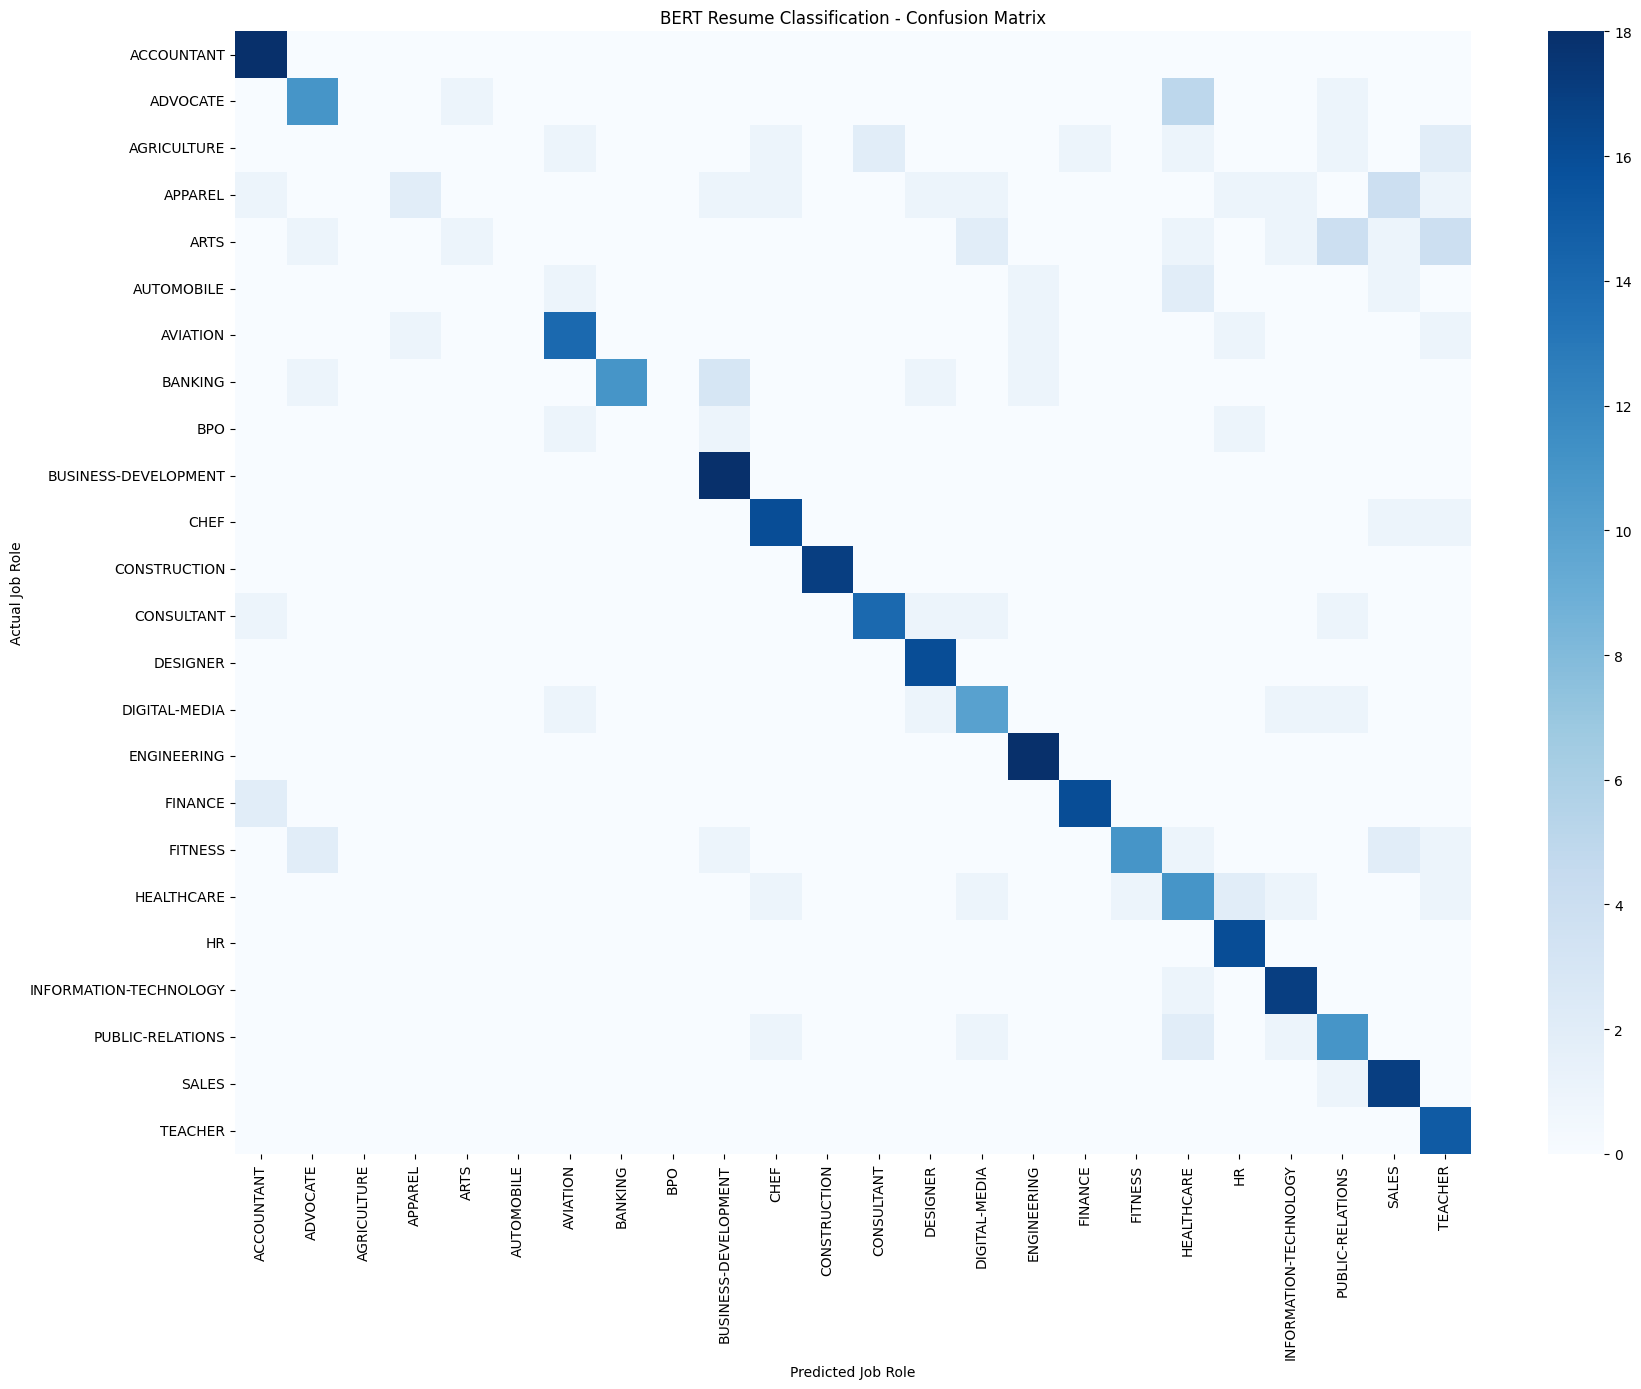

In [ ]:
# Step 18: Visualize the confusion matrix for test predictions
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(18, 14))
sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("BERT Resume Classification - Confusion Matrix")
plt.xlabel("Predicted Job Role")
plt.ylabel("Actual Job Role")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# Step 19: Predict the job category for a sample resume
def predict_job_role(resume_text):
    model.eval()

    inputs = tokenizer(
        resume_text,
        truncation=True,
        max_length=256,
        padding=True,
        return_tensors="pt"
    ).to(device)

    with torch.no_grad():
        outputs = model(**inputs)
        probabilities = torch.softmax(outputs.logits, dim=1)[0]

    top_indices = torch.topk(probabilities, k=3).indices.tolist()

    return [
        (
            label_encoder.inverse_transform([i])[0],
            round(probabilities[i].item() * 100, 2)
        )
        for i in top_indices
    ]

sample_resume = test_df.iloc[0]["Resume_str"]

print("Predictions:")
for role, score in predict_job_role(sample_resume):
    print(f"{role}: {score}%")

Predictions:
HR: 58.21%
CHEF: 3.18%
FITNESS: 2.61%


In [ ]:
# Step 20: Save the fine-tuned BERT model and label encoder
import os
import joblib

save_dir = "/content/bert_resume_model"
os.makedirs(save_dir, exist_ok=True)

trainer.save_model(save_dir)
tokenizer.save_pretrained(save_dir)
joblib.dump(label_encoder, os.path.join(save_dir, "label_encoder.pkl"))

print("Model saved successfully:", save_dir)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved successfully: /content/bert_resume_model


In [ ]:
# Step 21: Upload a resume PDF for screening
from google.colab import files

uploaded_resume = files.upload()

resume_path = next(iter(uploaded_resume))

print("Uploaded Resume:", resume_path)

Saving 50328713.pdf to 50328713.pdf
Uploaded Resume: 50328713.pdf


In [ ]:
# Step 22: Extract text from the uploaded PDF resume
!pip install -q pymupdf

import fitz

doc = fitz.open(resume_path)
resume_text = "\n".join(page.get_text() for page in doc)
doc.close()

print(resume_text[:2000])

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 24.6 MB/s eta 0:00:00
ENGINEERING INTERN
Skills
C++, Python, MATLAB, Git, Bash, R, SQL (basic). Experienced in Linux/Unix and using high performance computing clusters.
Machine Learning Tools and Libraries: Scikit-learn, Pandas, Seaborn, matplotlib, TensorFlow (basic). (I built a XGBoost
model that has 77.5% accuracy in the Kaggle Titanic challenge.)
Computational Fluid Dynamics and Discrete Element Method Codes
CFD-DEM, OpenFOAM, CFD-ACE+Â®, FluentÂ®, COMSOLÂ®, LAMMPS, and LIGGGHTS.
Reservoir and Fracture Modeling Tools
CMGÂ® for reservoir simulation; FracProÂ® for fracture simulation and analysis; Saphir for pressure transient analysis.
Experimental and Statistical Methods
SEM, AFM, Confocal Microscopy, Regression analysis, Statistical process control, Design of experiments.
Experience
ENGINEERING INTERN 08/2016 ï¼​ 12/2016 Company Name State
Project: Develop a cavings transport model for optimizing hole-cleaning operations.
De

In [ ]:
# Step 23: Load the saved BERT model and predict the resume category
import torch
import joblib
from transformers import AutoTokenizer, AutoModelForSequenceClassification

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

tokenizer = AutoTokenizer.from_pretrained(model_path)
model = AutoModelForSequenceClassification.from_pretrained(model_path)
model.to(device)
model.eval()

label_encoder = joblib.load(os.path.join(model_path, "label_encoder.pkl"))

inputs = tokenizer(
    resume_text,
    return_tensors="pt",
    truncation=True,
    padding=True,
    max_length=256
).to(device)

with torch.no_grad():
    outputs = model(**inputs)
    probabilities = torch.softmax(outputs.logits, dim=-1)[0]

top_indices = torch.topk(probabilities, k=3).indices.tolist()

print("Top 3 Predicted Job Roles:")
for idx in top_indices:
    role = label_encoder.inverse_transform([idx])[0]
    score = probabilities[idx].item() * 100
    print(f"{role}: {score:.2f}%")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Top 3 Predicted Job Roles:
ENGINEERING: 50.52%
CONSTRUCTION: 5.34%
CONSULTANT: 5.03%
